# Aplicación 3 — Biología/Química: predicción de propiedades moleculares con Graph Neural Networks

**Objetivo:** predecir la **solubilidad en agua** de una molécula a partir de su estructura, usando una red neuronal
sobre grafos (GNN) escrita desde cero en PyTorch.

Una molécula es naturalmente un **grafo**: los átomos son nodos y los enlaces son aristas. Las redes de *message
passing* (Gilmer et al., 2017) actualizan la representación de cada átomo agregando "mensajes" de sus vecinos;
tras varias capas, cada átomo "conoce" su entorno químico. Al final se agregan todos los átomos para obtener un
vector de la molécula completa.

Este es el núcleo de modelos usados en descubrimiento de fármacos (predicción de toxicidad, afinidad, ADMET) y de
herramientas como AlphaFold, que también razona sobre grafos de residuos.

**Dataset:** ESOL (Delaney, 2004) — 1128 moléculas con su solubilidad medida $\log S$ (mol/L). Es parte del
benchmark MoleculeNet. Se descarga automáticamente (~100 KB).

**Contenido**
1. Leer moléculas en formato SMILES y convertirlas a grafos (parser propio, sin RDKit).
2. Agrupar grafos de distinto tamaño en un *batch*.
3. Implementar una capa de *message passing* con `index_add_`.
4. Entrenar y comparar con la ecuación empírica ESOL y con un MLP sobre descriptores.

In [ ]:
import os
import re
import urllib.request
import numpy as np
import pandas as pd<
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"

URL = "https://deepchemdata.s3-us-west-1.amazonaws.com/datasets/delaney-processed.csv"
PATH = "data/delaney-processed.csv"
if not os.path.exists(PATH):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(URL, PATH)

df = pd.read_csv(PATH)
df["smiles"] = df["smiles"].str.strip()
TARGET = "measured log solubility in mols per litre"
print(df.shape)
df[["Compound ID", "smiles", TARGET]].head()

(1128, 10)


,Compound ID,smiles,measured log solubility in mols per litre
0,Amigdalin,OCC3OC(OCC2OC(OC(C#N)c1ccccc1)C(O)C(O)C2O)C(O)...,-0.77
1,Fenfuram,Cc1occc1C(=O)Nc2ccccc2,-3.30
2,citral,CC(C)=CCCC(C)=CC(=O),-2.06
3,Picene,c1ccc2c(c1)ccc3c2ccc4c5ccccc5ccc43,-7.87
4,Thiophene,c1ccsc1,-1.33


## 1. De SMILES a grafo

SMILES es una notación de texto para moléculas. Algunas reglas básicas:

| SMILES | Significado |
|---|---|
| `CCO` | etanol: C–C–O (los hidrógenos son implícitos) |
| `C=O`, `C#N` | enlace doble, triple |
| `CC(C)C` | paréntesis = ramificación |
| `c1ccccc1` | benceno: minúsculas = aromático; los dígitos abren y cierran anillos |
| `[N+](=O)[O-]` | corchetes para cargas o átomos especiales |

En la práctica se usa la librería **RDKit**, pero escribir un parser simple es un buen ejercicio y evita
dependencias. Este parser cubre todo lo que aparece en ESOL.

In [2]:
TOKEN_RE = re.compile(r"(\[[^\]]+\]|Br|Cl|%\d{2}|[BCNOPSFIbcnops]|\(|\)|\.|=|#|-|\+|\\|/|:|@|\d)")
BOND_ORDER = {"-": 1.0, "=": 2.0, "#": 3.0, ":": 1.5, "/": 1.0, "\\": 1.0}
VALENCE = {"B": 3, "C": 4, "N": 3, "O": 2, "P": 3, "S": 2, "F": 1, "Cl": 1, "Br": 1, "I": 1}

def parse_smiles(smiles):
    tokens = TOKEN_RE.findall(smiles)
    assert "".join(tokens) == smiles, f"no se pudo tokenizar {smiles}"
    atoms, bonds = [], []
    prev, branch_stack, rings, bond = None, [], {}, None

    def add_bond(i, j, order):
        if order is None:   # enlace implícito: aromático entre átomos aromáticos, simple en otro caso
            order = 1.5 if atoms[i]["aromatic"] and atoms[j]["aromatic"] else 1.0
        bonds.append((i, j, order))

    for tok in tokens:
        if tok == "(":
            branch_stack.append(prev)
        elif tok == ")":
            prev = branch_stack.pop()
        elif tok == ".":
            prev = None
        elif tok in BOND_ORDER:
            bond = BOND_ORDER[tok]
        elif tok[0].isdigit() or tok[0] == "%":          # apertura o cierre de anillo
            num = int(tok.lstrip("%"))
            if num in rings:
                j, ring_bond = rings.pop(num)
                add_bond(prev, j, bond if bond is not None else ring_bond)
            else:
                rings[num] = (prev, bond)
            bond = None
        else:                                              # un átomo
            if tok.startswith("["):
                m = re.match(r"\[(\d*)([A-Z][a-z]?|[cnops]|se)(@*)(H\d*)?([+-]+\d*)?", tok)
                symbol, hs, chg = m.group(2), m.group(4), m.group(5)
                n_h = 0 if not hs else (int(hs[1:]) if len(hs) > 1 else 1)
                charge = 0
                if chg:
                    sign = 1 if chg[0] == "+" else -1
                    charge = sign * (int(chg[1:]) if chg[1:].isdigit() else len(chg))
                explicit = True
            else:
                symbol, n_h, charge, explicit = tok, 0, 0, False
            atoms.append({"symbol": symbol.capitalize(), "aromatic": symbol.islower(),
                          "charge": charge, "n_h": n_h, "explicit": explicit})
            idx = len(atoms) - 1
            if prev is not None:
                add_bond(prev, idx, bond)
            prev, bond = idx, None
    assert not rings and not branch_stack, f"SMILES mal formado: {smiles}"

    for i, a in enumerate(atoms):                          # hidrógenos implícitos según la valencia
        if not a["explicit"]:
            used = sum(o for x, y, o in bonds if i in (x, y))
            a["n_h"] = max(0, int(round(VALENCE.get(a["symbol"], 0) - used)))
    return atoms, bonds

atoms, bonds = parse_smiles("O=C(O)c1ccccc1")   # ácido benzoico
for i, a in enumerate(atoms):
    print(i, a["symbol"], "aromático" if a["aromatic"] else "", f"H={a['n_h']}")
print("enlaces (i, j, orden):", bonds)

0 O  H=0
1 C  H=0
2 O  H=1
3 C aromático H=0
4 C aromático H=1
5 C aromático H=1
6 C aromático H=1
7 C aromático H=1
8 C aromático H=1
enlaces (i, j, orden): [(0, 1, 2.0), (1, 2, 1.0), (1, 3, 1.0), (3, 4, 1.5), (4, 5, 1.5), (5, 6, 1.5), (6, 7, 1.5), (7, 8, 1.5), (8, 3, 1.5)]


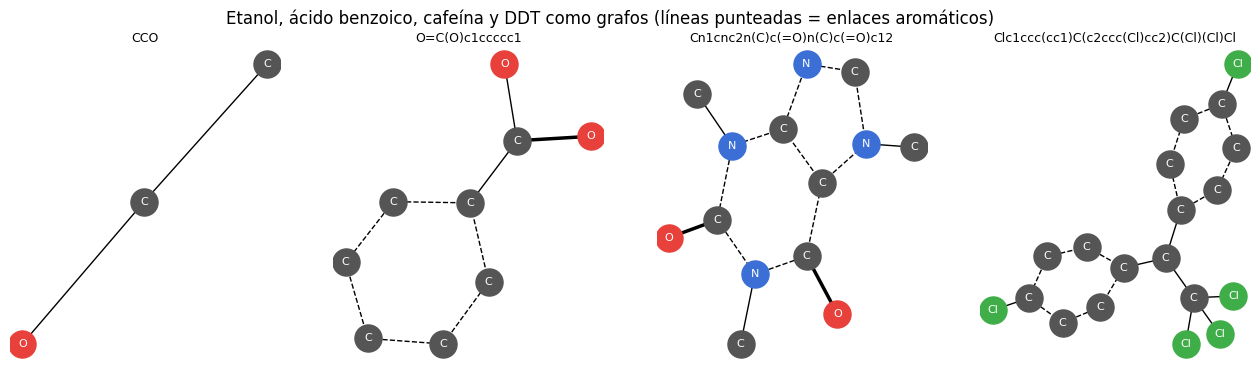

In [3]:
try:
    import networkx as nx
    def draw_molecule(smiles, ax):
        atoms, bonds = parse_smiles(smiles)
        G = nx.Graph()
        G.add_nodes_from(range(len(atoms)))
        G.add_edges_from((i, j) for i, j, _ in bonds)
        pos = nx.kamada_kawai_layout(G)
        colors = {"C": "#555555", "O": "#e8413c", "N": "#3b6fd6", "Cl": "#3fae49", "S": "#e0b000",
                  "F": "#7fd0d0", "Br": "#9b4a2a", "P": "#f08000", "I": "#7b2fa0"}
        for i, j, o in bonds:
            style = {1.0: "-", 1.5: "--", 2.0: "-", 3.0: "-"}[o]
            ax.plot(*zip(pos[i], pos[j]), style, color="k", lw=1 + (o >= 2) * 1.5, zorder=1)
        for i, a in enumerate(atoms):
            ax.scatter(*pos[i], s=380, color=colors.get(a["symbol"], "pink"), zorder=2)
            ax.text(*pos[i], a["symbol"], color="white", ha="center", va="center", fontsize=8, zorder=3)
        ax.set_title(smiles, fontsize=9); ax.axis("off")

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    for ax, s in zip(axes, ["CCO", "O=C(O)c1ccccc1", "Cn1cnc2n(C)c(=O)n(C)c(=O)c12", "Clc1ccc(cc1)C(c2ccc(Cl)cc2)C(Cl)(Cl)Cl"]):
        draw_molecule(s, ax)
    plt.suptitle("Etanol, ácido benzoico, cafeína y DDT como grafos (líneas punteadas = enlaces aromáticos)")
    plt.show()
except ImportError:
    print("Instala networkx para dibujar las moléculas (opcional).")

### Características de nodos y aristas

Cada átomo se describe con un vector *one-hot* de su elemento, número de vecinos, hidrógenos, carga y si es
aromático. Cada enlace, con su tipo (simple, doble, triple, aromático).

In [4]:
ELEMENTS = ["C", "N", "O", "S", "F", "Cl", "Br", "I", "P"]
BOND_TYPES = [1.0, 1.5, 2.0, 3.0]

def one_hot(value, choices):
    v = [0.0] * (len(choices) + 1)                      # la última posición = "otro"
    v[choices.index(value) if value in choices else -1] = 1.0
    return v

def mol_to_graph(smiles):
    atoms, bonds = parse_smiles(smiles)
    degree = [0] * len(atoms)
    for i, j, _ in bonds:
        degree[i] += 1; degree[j] += 1
    x = [one_hot(a["symbol"], ELEMENTS) + one_hot(degree[k], [0, 1, 2, 3, 4])
         + one_hot(a["n_h"], [0, 1, 2, 3]) + [float(a["aromatic"]), float(a["charge"])]
         for k, a in enumerate(atoms)]
    src, dst, e = [], [], []
    for i, j, o in bonds:                                # cada enlace como dos aristas dirigidas
        src += [i, j]; dst += [j, i]
        e += [one_hot(o, BOND_TYPES)[:-1]] * 2
    return {
        "x": torch.tensor(x, dtype=torch.float32),
        "edge_index": torch.tensor([src, dst], dtype=torch.long),
        "edge_attr": torch.tensor(e, dtype=torch.float32).reshape(-1, len(BOND_TYPES)),
    }

graphs = [mol_to_graph(s) for s in df["smiles"]]
y_all = torch.tensor(df[TARGET].values, dtype=torch.float32)
NODE_DIM, EDGE_DIM = graphs[0]["x"].shape[1], len(BOND_TYPES)
print("moléculas:", len(graphs), "| dim. nodo:", NODE_DIM, "| dim. arista:", EDGE_DIM)
print("átomos por molécula: min", min(len(g["x"]) for g in graphs), "max", max(len(g["x"]) for g in graphs))

moléculas: 1128 | dim. nodo: 23 | dim. arista: 4
átomos por molécula: min 1 max 55


## 2. Batching de grafos

Las moléculas tienen distinto número de átomos, así que no podemos apilarlas en un tensor rectangular. El truco
estándar (usado por PyTorch Geometric y DGL) es **unir todos los grafos del batch en un único grafo grande y
desconectado**:

- Se concatenan los nodos de todas las moléculas.
- Los índices de las aristas se desplazan según cuántos nodos hay antes.
- Un vector `batch` indica a qué molécula pertenece cada átomo (para el *pooling* final).

In [5]:
def collate_graphs(items):
    xs, eis, eas, batch, offset = [], [], [], [], 0
    for k, g in enumerate(items):
        n = g["x"].shape[0]
        xs.append(g["x"]); eas.append(g["edge_attr"])
        eis.append(g["edge_index"] + offset)
        batch.append(torch.full((n,), k, dtype=torch.long))
        offset += n
    return torch.cat(xs), torch.cat(eis, dim=1), torch.cat(eas), torch.cat(batch)

x, ei, ea, b = collate_graphs(graphs[:3])
print("nodos:", x.shape, "| aristas:", ei.shape, "| batch:", b.tolist())

nodos: torch.Size([58, 23]) | aristas: torch.Size([2, 120]) | batch: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2]


## 3. La capa de *message passing*

Para cada átomo $i$ con representación $h_i$:

$$m_i = \sum_{j \in \mathcal{N}(i)} \mathrm{MLP}_{msg}\big([h_j \,\|\, e_{ji}]\big), \qquad
h_i' = h_i + \mathrm{MLP}_{upd}\big([h_i \,\|\, m_i]\big)$$

La suma sobre vecinos se implementa con `index_add_`: sumamos cada mensaje en la fila de su átomo destino. La
conexión residual ($h_i + \dots$) ayuda a entrenar redes más profundas.

Para la molécula completa usamos *pooling* de suma y de media sobre todos los átomos, y un MLP final produce $\log S$.

In [6]:
class MessagePassing(nn.Module):
    def __init__(self, dim, edge_dim):
        super().__init__()
        self.msg = nn.Sequential(nn.Linear(dim + edge_dim, dim), nn.SiLU(), nn.Linear(dim, dim))
        self.upd = nn.Sequential(nn.Linear(2 * dim, dim), nn.SiLU(), nn.Linear(dim, dim))
        self.norm = nn.LayerNorm(dim)

    def forward(self, h, edge_index, edge_attr):
        src, dst = edge_index
        messages = self.msg(torch.cat([h[src], edge_attr], dim=1))
        agg = torch.zeros_like(h).index_add_(0, dst, messages)     # suma de mensajes por átomo destino
        return self.norm(h + self.upd(torch.cat([h, agg], dim=1)))

def global_pool(h, batch, n_graphs):
    total = torch.zeros(n_graphs, h.shape[1], device=h.device).index_add_(0, batch, h)
    count = torch.zeros(n_graphs, device=h.device).index_add_(0, batch, torch.ones_like(batch, dtype=h.dtype))
    return torch.cat([total, total / count.unsqueeze(1)], dim=1)   # [suma | media]

class MolGNN(nn.Module):
    def __init__(self, node_dim, edge_dim, hidden=128, layers=4):
        super().__init__()
        self.embed = nn.Linear(node_dim, hidden)
        self.layers = nn.ModuleList([MessagePassing(hidden, edge_dim) for _ in range(layers)])
        self.head = nn.Sequential(nn.Linear(2 * hidden, hidden), nn.SiLU(), nn.Dropout(0.1), nn.Linear(hidden, 1))

    def forward(self, x, edge_index, edge_attr, batch, n_graphs):
        h = self.embed(x)
        for layer in self.layers:
            h = layer(h, edge_index, edge_attr)
        return self.head(global_pool(h, batch, n_graphs)).squeeze(-1)

## 4. Entrenamiento

División aleatoria 80/10/10. Normalizamos el objetivo con la media y desviación de train para estabilizar el
entrenamiento, y guardamos el modelo con mejor error en validación.

Parámetros: 368,897


época  15 | RMSE train 0.728 | val 0.833


época  30 | RMSE train 0.641 | val 0.737


época  45 | RMSE train 0.579 | val 0.699


época  60 | RMSE train 0.484 | val 0.674


...

época  90 | RMSE train 0.409 | val 0.645


época 105 | RMSE train 0.353 | val 0.627


época 120 | RMSE train 0.325 | val 0.634


época 135 | RMSE train 0.312 | val 0.630


época 150 | RMSE train 0.309 | val 0.632


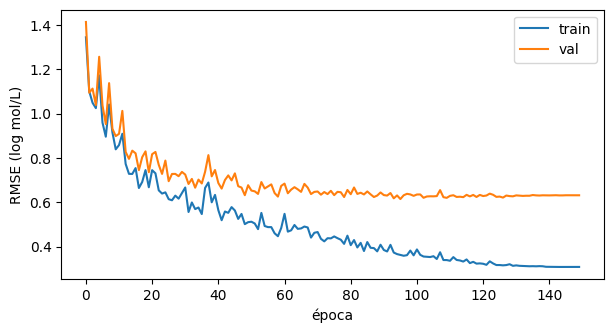

In [7]:
perm = torch.randperm(len(graphs), generator=torch.Generator().manual_seed(42))
n_tr, n_va = int(0.8 * len(perm)), int(0.9 * len(perm))
idx_train, idx_val, idx_test = perm[:n_tr], perm[n_tr:n_va], perm[n_va:]
y_mean, y_std = y_all[idx_train].mean(), y_all[idx_train].std()

def batches(indices, batch_size, shuffle):
    order = indices[torch.randperm(len(indices))] if shuffle else indices
    for k in range(0, len(order), batch_size):
        chunk = order[k:k + batch_size]
        x, ei, ea, b = collate_graphs([graphs[i] for i in chunk])
        yield x.to(device), ei.to(device), ea.to(device), b.to(device), len(chunk), y_all[chunk].to(device)

def predict(model, indices):
    model.eval()
    preds = []
    with torch.no_grad():
        for x, ei, ea, b, n, _ in batches(indices, 256, shuffle=False):
            preds.append(model(x, ei, ea, b, n) * y_std + y_mean)
    return torch.cat(preds).cpu()

def rmse(pred, indices):
    return torch.sqrt(F.mse_loss(pred, y_all[indices])).item()

model = MolGNN(NODE_DIM, EDGE_DIM).to(device)
print(f"Parámetros: {sum(p.numel() for p in model.parameters()):,}")
EPOCHS = 150
opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS)
best, best_state, log = float("inf"), None, []
for epoch in range(EPOCHS):
    model.train()
    for x, ei, ea, b, n, y in batches(idx_train, 32, shuffle=True):
        loss = F.mse_loss(model(x, ei, ea, b, n), (y - y_mean.to(device)) / y_std.to(device))
        opt.zero_grad(); loss.backward(); opt.step()
    sched.step()
    tr, va = rmse(predict(model, idx_train), idx_train), rmse(predict(model, idx_val), idx_val)
    log.append((tr, va))
    if va < best:
        best, best_state = va, {k: v.clone() for k, v in model.state_dict().items()}
    if (epoch + 1) % 15 == 0:
        print(f"época {epoch + 1:3d} | RMSE train {tr:.3f} | val {va:.3f}")
model.load_state_dict(best_state)

plt.figure(figsize=(7, 3.5))
plt.plot([l[0] for l in log], label="train"); plt.plot([l[1] for l in log], label="val")
plt.ylabel("RMSE (log mol/L)"); plt.xlabel("época"); plt.legend(); plt.show()

## 5. Evaluación y comparación con modelos de referencia

- **Ecuación ESOL** (Delaney, 2004): regresión lineal con 4 descriptores diseñados por químicos (logP, peso
  molecular, enlaces rotables, proporción aromática). Sus predicciones vienen en el CSV.
- **MLP sobre descriptores**: una red densa con los descriptores tabulares del CSV (peso molecular, donadores de
  puentes de hidrógeno, anillos, enlaces rotables, área polar).

La GNN no recibe ningún descriptor calculado: aprende directamente de la estructura del grafo.

Ecuación ESOL (Delaney)   RMSE test = 0.930
MLP sobre descriptores    RMSE test = 0.866
GNN (este notebook)       RMSE test = 0.495


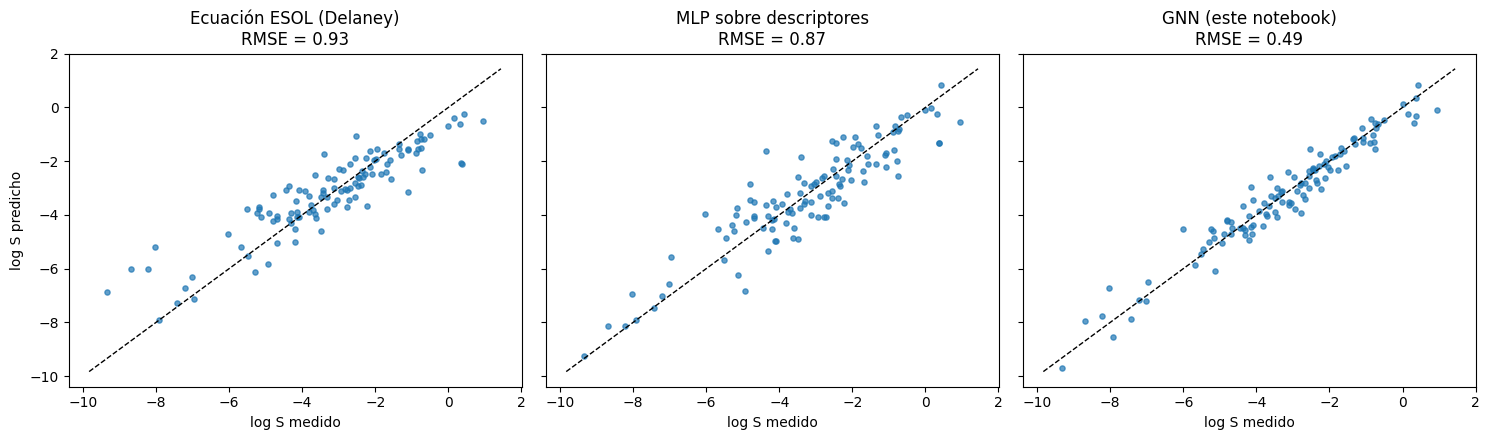

In [8]:
pred_gnn = predict(model, idx_test)
pred_esol = torch.tensor(df["ESOL predicted log solubility in mols per litre"].values, dtype=torch.float32)[idx_test]

desc_cols = ["Molecular Weight", "Number of H-Bond Donors", "Number of Rings",
             "Number of Rotatable Bonds", "Polar Surface Area", "Minimum Degree"]
D = torch.tensor(df[desc_cols].values, dtype=torch.float32)
D = (D - D[idx_train].mean(0)) / D[idx_train].std(0)
torch.manual_seed(0)
mlp = nn.Sequential(nn.Linear(len(desc_cols), 64), nn.SiLU(), nn.Linear(64, 64), nn.SiLU(), nn.Linear(64, 1))
opt_mlp = torch.optim.Adam(mlp.parameters(), lr=3e-3, weight_decay=1e-4)
best_mlp, best_mlp_state = float("inf"), None
for epoch in range(500):
    loss = F.mse_loss(mlp(D[idx_train]).squeeze(-1), y_all[idx_train])
    opt_mlp.zero_grad(); loss.backward(); opt_mlp.step()
    with torch.no_grad():
        va = F.mse_loss(mlp(D[idx_val]).squeeze(-1), y_all[idx_val]).item()
    if va < best_mlp:
        best_mlp, best_mlp_state = va, {k: v.clone() for k, v in mlp.state_dict().items()}
mlp.load_state_dict(best_mlp_state)
with torch.no_grad():
    pred_mlp = mlp(D[idx_test]).squeeze(-1)

results = {"Ecuación ESOL (Delaney)": pred_esol, "MLP sobre descriptores": pred_mlp, "GNN (este notebook)": pred_gnn}
for name, p in results.items():
    print(f"{name:25s} RMSE test = {rmse(p, idx_test):.3f}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharey=True)
y_test = y_all[idx_test]
for ax, (name, p) in zip(axes, results.items()):
    ax.scatter(y_test, p, s=14, alpha=0.7)
    lims = [y_test.min() - 0.5, y_test.max() + 0.5]
    ax.plot(lims, lims, "k--", lw=1)
    ax.set_title(f"{name}\nRMSE = {rmse(p, idx_test):.2f}")
    ax.set_xlabel("log S medido")
axes[0].set_ylabel("log S predicho")
plt.tight_layout(); plt.show()

## 6. Usar el modelo con moléculas nuevas

In [9]:
def predict_smiles(smiles_list):
    gs = [mol_to_graph(s) for s in smiles_list]
    x, ei, ea, b = collate_graphs(gs)
    model.eval()
    with torch.no_grad():
        out = model(x.to(device), ei.to(device), ea.to(device), b.to(device), len(gs)) * y_std + y_mean
    return out.cpu()

candidates = {
    "metanol": "CO",
    "glucosa": "OCC1OC(O)C(O)C(O)C1O",
    "benceno": "c1ccccc1",
    "naftaleno": "c1ccc2ccccc2c1",
    "ibuprofeno": "CC(C)Cc1ccc(cc1)C(C)C(=O)O",
    "antraceno": "c1ccc2cc3ccccc3cc2c1",
}
for (name, s), p in zip(candidates.items(), predict_smiles(list(candidates.values()))):
    print(f"{name:12s} {s:30s} log S predicho = {p:+.2f}")

metanol      CO                             log S predicho = +1.59
glucosa      OCC1OC(O)C(O)C(O)C1O           log S predicho = +0.32
benceno      c1ccccc1                       log S predicho = -1.92
naftaleno    c1ccc2ccccc2c1                 log S predicho = -3.55
ibuprofeno   CC(C)Cc1ccc(cc1)C(C)C(=O)O     log S predicho = -2.72
antraceno    c1ccc2cc3ccccc3cc2c1           log S predicho = -5.69


Las tendencias tienen sentido químico: moléculas pequeñas y con grupos –OH (metanol, glucosa) son solubles; los
hidrocarburos aromáticos se vuelven menos solubles a medida que crece el número de anillos.
(Ojo: varias de estas moléculas están en ESOL, quizá en el conjunto de entrenamiento; prueba con moléculas que
no estén en el CSV para una evaluación honesta.)

## 7. Siguientes pasos

- Con **RDKit** + **PyTorch Geometric** este pipeline se reduce a unas pocas líneas
  (`torch_geometric.datasets.MoleculeNet(root, "ESOL")`) y se tiene acceso a capas como `GINEConv`, `GATConv`,
  `SchNet` y `DimeNet` (estas dos últimas usan coordenadas 3D).
- Otros datasets de MoleculeNet: **Tox21** (toxicidad, clasificación multitarea), **BBBP** (paso de la barrera
  hematoencefálica), **QM9** (propiedades cuánticas de 134 mil moléculas).
- En biología de proteínas, el mismo paradigma aparece en predicción de estructura y diseño (AlphaFold, RFdiffusion).

**Ejercicios**
1. Cambia la suma de mensajes por un promedio o un máximo. ¿Cómo afecta el RMSE?
2. Varía el número de capas (1 a 6). ¿Por qué con 1 capa la red sólo "ve" vecinos directos?
3. Implementa atención sobre los vecinos (estilo GAT) en lugar de una suma simple.
4. La división aleatoria es optimista: implementa una división por *scaffold* (núcleo molecular) y compara.